# 004 Easy — Trajectory

`P_max, cN2_max, L_inj, dip_frac, x_of` + `z_mm` → `E_MeV, q_pC, dE_pct, emit_um, div_mrad, sigz_um`

## Setup

In [1]:
from xgboost import XGBRegressor  # before torch (OpenMP clash on macOS)

import copy
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, train_test_split
from sklearn.multioutput import MultiOutputRegressor
from sklearn.preprocessing import StandardScaler

from pallas_score import normalised_to_physical, physical_to_normalised, score_submission
from physics_formulas import electrons_background, energy_gain_MeV, m3_to_cm3, species_B

torch.set_num_threads(1)

PACK = "/Users/netanmangal/Documents/netanmangal/ganil-artifact-hackathon-2026/challenges/surrogate-models/full-data"
TASK = "trajectory"
TARGETS = ['E_MeV', 'q_pC', 'dE_pct', 'emit_um', 'div_mrad', 'sigz_um']
FEATURES = ['P_max', 'cN2_max', 'L_inj', 'dip_frac', 'x_of', 'z_mm']
EPOCHS = 40
BATCH = 512
XGB_TREES = 300
HIDDEN = [256, 512, 64]
LOSS = nn.HuberLoss()
EPOCHS_RES = 60


def add_physics(frame):
    frame = frame.copy()
    frame["dz"] = frame.z_mm - (frame.L_inj + 3.2)
    frame["in_plasma"] = (frame.dz <= 0).astype(float)
    frame["n_e"] = frame.P_max * (1 - 0.3 * frame.cN2_max)
    frame["n_N2"] = frame.P_max * frame.cN2_max
    frame["gain"] = 0.0
    for config, rows in frame.groupby("config"):
        row = rows.iloc[0]
        z = np.linspace(0, (row.L_inj + 3.2) * 1e3, 500)
        n_He, n_N = species_B(z, row.P_max, row.cN2_max, row.L_inj, row.dip_frac)
        n_e = m3_to_cm3(electrons_background(n_He, n_N))
        gain = energy_gain_MeV(z, n_e, eta=0.27)
        frame.loc[rows.index, "gain"] = np.interp(rows.z_mm * 1e3, z, gain)
    return frame


def features(frame):
    return frame[FEATURES + ["dz", "in_plasma", "n_e", "n_N2", "gain"]].to_numpy()


def targets(frame):
    columns = []
    for t in TARGETS:
        columns.append(physical_to_normalised(t, frame[t]))
    return np.column_stack(columns)


def physical(pred):
    out = pd.DataFrame()
    for i, t in enumerate(TARGETS):
        out[t] = normalised_to_physical(t, pred[:, i])
    return out


def score(pred, frame, zone=None):
    pred = physical(pred)
    pred.insert(0, "z_mm", frame.z_mm.to_numpy())
    pred.insert(0, "config", frame.config.to_numpy())
    return score_submission(pred, frame[["config", "z_mm", "L_inj"] + TARGETS], zone=zone)


data = add_physics(pd.read_parquet(f"{PACK}/campaign_B_trajectories.parquet"))
test_inputs = add_physics(pd.read_parquet(f"{PACK}/test_trajectory.parquet"))
configs = data.config.unique()

train_configs, test_configs = train_test_split(configs, test_size=0.2, random_state=0)
train = data[data.config.isin(train_configs)]
test = data[data.config.isin(test_configs)]
print(f"{len(configs):,} configs x {data.z_mm.nunique()} positions, {len(train_configs):,} train / {len(test_configs):,} test configs")

2,855 configs x 113 positions, 2,284 train / 571 test configs


## Random forest

In [2]:
rf = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=0)
rf.fit(features(train), targets(train))
score(rf.predict(features(test)), test)

{'E_MeV': 0.9395434989939703,
 'q_pC': 0.8527846480379276,
 'dE_pct': 0.7396745820221902,
 'emit_um': 0.7351051146816732,
 'div_mrad': 0.8645175216853376,
 'sigz_um': 0.8177766907185438,
 'mean': 0.8249003426899405,
 'n_rows': 23441,
 'n_z_scored': 44,
 'n_z_dropped': 1}

## XGBoost

In [3]:
xgb = MultiOutputRegressor(XGBRegressor(n_estimators=XGB_TREES, learning_rate=0.05, max_depth=7,
                                        subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=0))
xgb.fit(features(train), targets(train))
score(xgb.predict(features(test)), test)

{'E_MeV': 0.9668545277415098,
 'q_pC': 0.9384254331058907,
 'dE_pct': 0.7891077206804207,
 'emit_um': 0.8897666078851569,
 'div_mrad': 0.9681999203512148,
 'sigz_um': 0.8929454846668604,
 'mean': 0.9075499490718423,
 'n_rows': 23441,
 'n_z_scored': 44,
 'n_z_dropped': 1}

## MLP

In [4]:
def build_mlp(n_inputs):
    return nn.Sequential(
        nn.Linear(n_inputs, HIDDEN[0]), nn.ReLU(),
        nn.Linear(HIDDEN[0], HIDDEN[1]), nn.ReLU(),
        nn.Linear(HIDDEN[1], HIDDEN[2]), nn.ReLU(),
        nn.Linear(HIDDEN[2], len(TARGETS)),
    )


def fit_model(train, val, seed, build=build_mlp, epochs=EPOCHS):
    torch.manual_seed(seed)
    scaler = StandardScaler().fit(features(train))
    y_mean = targets(train).mean(0)
    y_std = targets(train).std(0)

    X = torch.tensor(scaler.transform(features(train)), dtype=torch.float32)
    y = torch.tensor((targets(train) - y_mean) / y_std, dtype=torch.float32)
    if val is not None:
        X_val = torch.tensor(scaler.transform(features(val)), dtype=torch.float32)
        y_val = torch.tensor((targets(val) - y_mean) / y_std, dtype=torch.float32)

    net = build(X.shape[1])
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)

    val_loss = []
    best_net = net
    for epoch in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad()
            loss = LOSS(net(X[idx]), y[idx])
            loss.backward()
            opt.step()
        sched.step()
        if val is not None:
            with torch.no_grad():
                val_loss.append(LOSS(net(X_val), y_val).item())
            if val_loss[-1] == min(val_loss):
                best_net = copy.deepcopy(net)

    return {"net": best_net, "scaler": scaler, "y_mean": y_mean, "y_std": y_std, "val_loss": val_loss}


def fit_mlp(train, val, seed):
    return fit_model(train, val, seed)


def predict_mlp(model, X):
    X = torch.tensor(model["scaler"].transform(X), dtype=torch.float32)
    with torch.no_grad():
        out = model["net"](X).numpy()
    return out * model["y_std"] + model["y_mean"]


def predict_ensemble(models, X):
    preds = []
    for model in models:
        preds.append(predict_mlp(model, X))
    return np.mean(preds, axis=0)


mlp = fit_mlp(train, test, seed=0)
print(f"best val loss {min(mlp['val_loss']):.4f} at epoch {np.argmin(mlp['val_loss']) + 1}")
score(predict_mlp(mlp, features(test)), test)

best val loss 0.0049 at epoch 39


{'E_MeV': 0.9966997914770622,
 'q_pC': 0.9982025962627219,
 'dE_pct': 0.9840307232159969,
 'emit_um': 0.9814195120294636,
 'div_mrad': 0.9876668174262502,
 'sigz_um': 0.9772515128493744,
 'mean': 0.9875451588768115,
 'n_rows': 23441,
 'n_z_scored': 44,
 'n_z_dropped': 1}

## Residual MLP

Three residual blocks of width 512.

In [5]:
class ResidualMLP(nn.Module):
    def __init__(self, n_inputs, width=512, n_blocks=3):
        super().__init__()
        self.inp = nn.Linear(n_inputs, width)
        self.blocks = nn.ModuleList()
        for _ in range(n_blocks):
            self.blocks.append(nn.Sequential(nn.Linear(width, width), nn.ReLU(), nn.Linear(width, width)))
        self.out = nn.Linear(width, len(TARGETS))

    def forward(self, x):
        h = torch.relu(self.inp(x))
        for block in self.blocks:
            h = torch.relu(h + block(h))
        return self.out(h)


def build_resnet(n_inputs):
    return ResidualMLP(n_inputs)


resnet = fit_model(train, test, seed=0, build=build_resnet, epochs=EPOCHS_RES)
print(f"best val loss {min(resnet['val_loss']):.4f} at epoch {np.argmin(resnet['val_loss']) + 1}")
score(predict_mlp(resnet, features(test)), test)

best val loss 0.0043 at epoch 51


{'E_MeV': 0.9982092935461792,
 'q_pC': 0.9993934626700003,
 'dE_pct': 0.9869045218365929,
 'emit_um': 0.9808905425500224,
 'div_mrad': 0.9921328826748814,
 'sigz_um': 0.9848354724834957,
 'mean': 0.990394362626862,
 'n_rows': 23441,
 'n_z_scored': 44,
 'n_z_dropped': 1}

## Residual ensemble

Three seeds averaged.

In [6]:
ensemble = [resnet]
for seed in (1, 2):
    ensemble.append(fit_model(train, test, seed, build=build_resnet, epochs=EPOCHS_RES))
score(predict_ensemble(ensemble, features(test)), test)

{'E_MeV': 0.9987586684801594,
 'q_pC': 0.9995401695821692,
 'dE_pct': 0.988382087553525,
 'emit_um': 0.9820730429492085,
 'div_mrad': 0.9931890312093915,
 'sigz_um': 0.9861458227427727,
 'mean': 0.9913481370862044,
 'n_rows': 23441,
 'n_z_scored': 44,
 'n_z_dropped': 1}

## Cross validation

In [7]:
rows = []
curves = []
for k, (train_idx, val_idx) in enumerate(KFold(5, shuffle=True, random_state=0).split(configs)):
    tr = data[data.config.isin(configs[train_idx])]
    va = data[data.config.isin(configs[val_idx])]

    rf_k = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=0)
    rf_k.fit(features(tr), targets(tr))
    xgb_k = MultiOutputRegressor(XGBRegressor(n_estimators=XGB_TREES, learning_rate=0.05, max_depth=7,
                                              subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=0))
    xgb_k.fit(features(tr), targets(tr))
    mlp_k = fit_mlp(tr, va, seed=k)
    curves.append(mlp_k["val_loss"])
    resnet_k = fit_model(tr, va, seed=k, build=build_resnet, epochs=EPOCHS_RES)

    rows.append({
        "rf": score(rf_k.predict(features(va)), va)["mean"],
        "xgb": score(xgb_k.predict(features(va)), va)["mean"],
        "mlp": score(predict_mlp(mlp_k, features(va)), va)["mean"],
        "resnet": score(predict_mlp(resnet_k, features(va)), va)["mean"],
    })
    print(f"fold {k}  mlp best val loss {min(mlp_k['val_loss']):.4f} at epoch {np.argmin(mlp_k['val_loss']) + 1}")

cv = pd.DataFrame(rows)
cv.loc["mean"] = cv.mean()
cv.loc["std"] = cv.iloc[:-1].std()
cv.round(4)

fold 0  mlp best val loss 0.0049 at epoch 39


fold 1  mlp best val loss 0.0049 at epoch 34


fold 2  mlp best val loss 0.0055 at epoch 38


fold 3  mlp best val loss 0.0054 at epoch 39


fold 4  mlp best val loss 0.0050 at epoch 38


,rf,xgb,mlp,resnet
0,0.8249,0.9075,0.9875,0.9904
1,0.8203,0.9164,0.9876,0.9904
2,0.8235,0.9132,0.9850,0.9883
3,0.8373,0.9195,0.9877,0.9895
4,0.8261,0.9173,0.9868,0.9899
mean,0.8264,0.9148,0.9869,0.9897
std,0.0064,0.0046,0.0012,0.0009


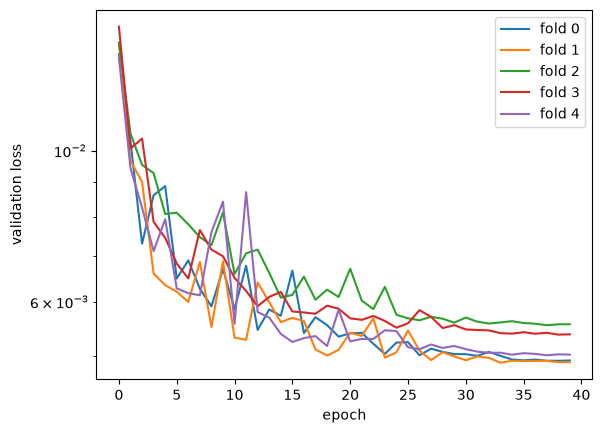

In [8]:
for k, curve in enumerate(curves):
    plt.plot(curve, label=f"fold {k}")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.legend()
plt.show()

## Final model on every configuration

The learning curve was still rising at 80 % of the data, so the submission model uses all of it.

In [9]:
final = []
for seed in (0, 1, 2):
    final.append(fit_model(data, None, seed, build=build_resnet, epochs=EPOCHS_RES))
print("trained on all", data.config.nunique(), "configurations")

trained on all 2855 configurations


## Submission

In [10]:
submission = physical(predict_ensemble(final, features(test_inputs)))
submission.insert(0, "z_mm", test_inputs.z_mm.to_numpy())
submission.insert(0, "config", test_inputs.config.to_numpy())
submission.to_csv("submission_trajectory.csv", index=False)
print(f"wrote submission_trajectory.csv ({len(submission):,} rows)")

wrote submission_trajectory.csv (40,341 rows)


## Save for the Hopsworks registry

In [11]:
name = f"lsr_{TASK}_mlp"
path = f"models/{name}"
os.makedirs(path, exist_ok=True)
for seed, model in enumerate(final):
    torch.save(model["net"].state_dict(), f"{path}/model_seed{seed}.pt")
    np.savez(f"{path}/scaler_seed{seed}.npz", x_mean=model["scaler"].mean_, x_std=model["scaler"].scale_,
             y_mean=model["y_mean"], y_std=model["y_std"])

scores = score(predict_ensemble(ensemble, features(test)), test)
metrics = {}
for t in TARGETS:
    metrics[f"holdout_r2_{t}"] = round(scores[t], 4)
metrics["holdout_mean_r2"] = round(scores["mean"], 4)
metrics["cv_mean_r2"] = round(float(cv.loc["mean", "resnet"]), 4)
metrics["holdout_drift_mean_r2"] = round(score(predict_ensemble(ensemble, features(test)), test, zone="drift")["mean"], 4)
json.dump({"task": TASK, "model": "mlp", "features": FEATURES, "targets": TARGETS, "metrics": metrics},
          open(f"{path}/meta.json", "w"), indent=1)
metrics

{'holdout_r2_E_MeV': 0.9988,
 'holdout_r2_q_pC': 0.9995,
 'holdout_r2_dE_pct': 0.9884,
 'holdout_r2_emit_um': 0.9821,
 'holdout_r2_div_mrad': 0.9932,
 'holdout_r2_sigz_um': 0.9861,
 'holdout_mean_r2': 0.9913,
 'cv_mean_r2': 0.9897,
 'holdout_drift_mean_r2': 0.9903}

## Comparison

In [12]:
table = pd.DataFrame({
    "rf": score(rf.predict(features(test)), test),
    "xgb": score(xgb.predict(features(test)), test),
    "mlp": score(predict_mlp(mlp, features(test)), test),
    "resnet": score(predict_mlp(resnet, features(test)), test),
    "ensemble": score(predict_ensemble(ensemble, features(test)), test),
    "ensemble, drift": score(predict_ensemble(ensemble, features(test)), test, zone="drift"),
    "internal emulator (medium bar)": {"E_MeV": 0.9633, "q_pC": 0.9331, "dE_pct": 0.8092, "emit_um": 0.8610, "div_mrad": 0.9469, "sigz_um": 0.8623, "mean": 0.8960},
})
table.T[TARGETS + ["mean"]].round(3)

,E_MeV,q_pC,dE_pct,emit_um,div_mrad,sigz_um,mean
rf,0.940,0.853,0.740,0.735,0.865,0.818,0.825
xgb,0.967,0.938,0.789,0.890,0.968,0.893,0.908
mlp,0.997,0.998,0.984,0.981,0.988,0.977,0.988
resnet,0.998,0.999,0.987,0.981,0.992,0.985,0.990
ensemble,0.999,1.000,0.988,0.982,0.993,0.986,0.991
"ensemble, drift",0.999,0.999,0.985,NaN,NaN,0.978,0.990
internal emulator (medium bar),0.963,0.933,0.809,0.861,0.947,0.862,0.896
